# MRP convergence diagnostics

Checks that the multilevel model in `wawv.estimators` converged before its estimates are reported. Run `make estimate` first; it saves the posterior to `models/mrp_idata.nc`.

**Targets:** R̂ < 1.01 for every parameter, bulk and tail ESS > 400, zero divergent transitions.

In [1]:
import sys; sys.path.insert(0, '../src')
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
from wawv import config
from wawv.states import ABBR
from wawv.viz import apply_style
apply_style()
%matplotlib inline
idata = az.from_netcdf(config.MODEL_DIR / 'mrp_idata.nc')
idata

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:                   (chain: 4, draw: 2000, sex_dim: 1,
│                                      state_fips__factor_dim: 51,
│                                      age_grp__factor_dim: 4, race__factor_dim: 5,
│                                      educ__factor_dim: 5, race:educ__factor_dim: 25,
│                                      age_grp:educ__factor_dim: 20)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 16kB 0 1 2 3 ... 1996 1997 1998 1999
│         * sex_dim                   (sex_dim) <U4 16B 'male'
│         * state_fips__factor_dim    (state_fips__factor_dim) <U2 408B '1' '10' ... '9'
│         * age_grp__factor_dim       (age_grp__factor_dim) <U5 80B '18-29' ... '65+'
│         * race__factor_dim          (race__factor_dim) <U8 160B 'asian' ... 'white'
│         * educ__factor_dim          (educ__factor_dim) <U12 240B 'ba' ... 'some_col...
│         * race:educ__factor_dim     (race:educ__factor_dim) <U21 2kB 'asian:ba' ......
│         * age_grp:educ__factor_dim  (age_grp:educ__factor_dim) <U18 1kB '18-29:ba' ...
│       Data variables: (12/15)
│           Intercept                 (chain, draw) float64 64kB ...
│           dem_2020_c                (chain, draw) float64 64kB ...
│           sex                       (chain, draw, sex_dim) float64 64kB ...
│           1|state_fips_sigma        (chain, draw) float64 64kB ...
│           1|age_grp_sigma           (chain, draw) float64 64kB ...
│           1|race_sigma              (chain, draw) float64 64kB ...
│           ...                        ...
│           1|state_fips              (chain, draw, state_fips__factor_dim) float64 3MB ...
│           1|age_grp                 (chain, draw, age_grp__factor_dim) float64 256kB ...
│           1|race                    (chain, draw, race__factor_dim) float64 320kB ...
│           1|educ                    (chain, draw, educ__factor_dim) float64 320kB ...
│           1|race:educ               (chain, draw, race:educ__factor_dim) float64 2MB ...
│           1|age_grp:educ            (chain, draw, age_grp:educ__factor_dim) float64 1MB ...
│       Attributes:
│           created_at:                  2026-11-13T20:51:08.294773+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.1
│           creation_library_language:   Python
│           inference_library:           pymc
│           inference_library_version:   6.4.0
│           sample_dims:                 ['chain', 'draw']
│           sampling_time:               864.9628469944
│           tuning_steps:                2000
│           modeling_interface:          bambi
│           modeling_interface_version:  0.21.0
├── Group: /sample_stats
│       Dimensions:                (chain: 4, draw: 2000)
│       Coordinates:
│         * chain                  (chain) int64 32B 0 1 2 3
│         * draw                   (draw) int64 16kB 0 1 2 3 4 ... 1996 1997 1998 1999
│       Data variables: (12/18)
│           step_size_bar          (chain, draw) float64 64kB ...
│           diverging              (chain, draw) bool 8kB ...
│           largest_eigval         (chain, draw) float64 64kB ...
│           n_steps                (chain, draw) float64 64kB ...
│           step_size              (chain, draw) float64 64kB ...
│           perf_counter_start     (chain, draw) float64 64kB ...
│           ...                     ...
│           perf_counter_diff      (chain, draw) float64 64kB ...
│           reached_max_treedepth  (chain, draw) bool 8kB ...
│           energy                 (chain, draw) float64 64kB ...
│           energy_error           (chain, draw) float64 64kB ...
│           tree_depth             (chain, draw) int64 64kB ...
│           process_time_diff      (chain, draw) float64 64kB ...
│       Attributes:
│           created_at:                  2026-11-13T20

## 1. Summary table
Worst $\hat{R}$ and lowest ESS first.

In [2]:
summ = az.summary(idata, kind='diagnostics', round_to=4)
print('divergences:', int(idata.sample_stats['diverging'].sum()))
summ.sort_values('r_hat', ascending=False).head(15)

divergences: 0


,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
1|state_fips[10],13457.2972,6009.5489,1.0024,0.0012,0.0018
1|educ_sigma,3703.1409,4776.1771,1.0021,0.0053,0.0100
1|state_fips[4],6625.3922,5628.4650,1.0016,0.0009,0.0007
1|state_fips[11],12141.9815,6033.2752,1.0016,0.0019,0.0028
1|state_fips_sigma,2351.5813,3424.2934,1.0014,0.0006,0.0003
1|state_fips[34],5382.8311,5250.4992,1.0013,0.0010,0.0008
1|state_fips[16],10765.4386,6296.8039,1.0013,0.0012,0.0015
1|state_fips[49],9243.3984,6018.3333,1.0012,0.0011,0.0012
1|age_grp:educ[30-44:lt_hs],10915.4062,5986.0805,1.0012,0.0013,0.0020
1|state_fips[30],14401.1852,6651.3729,1.0012,0.0011,0.0015


## 2. Group-level standard deviations
These hierarchical scale parameters are the hardest to sample. Each chain's trace should look like overlapping noise.

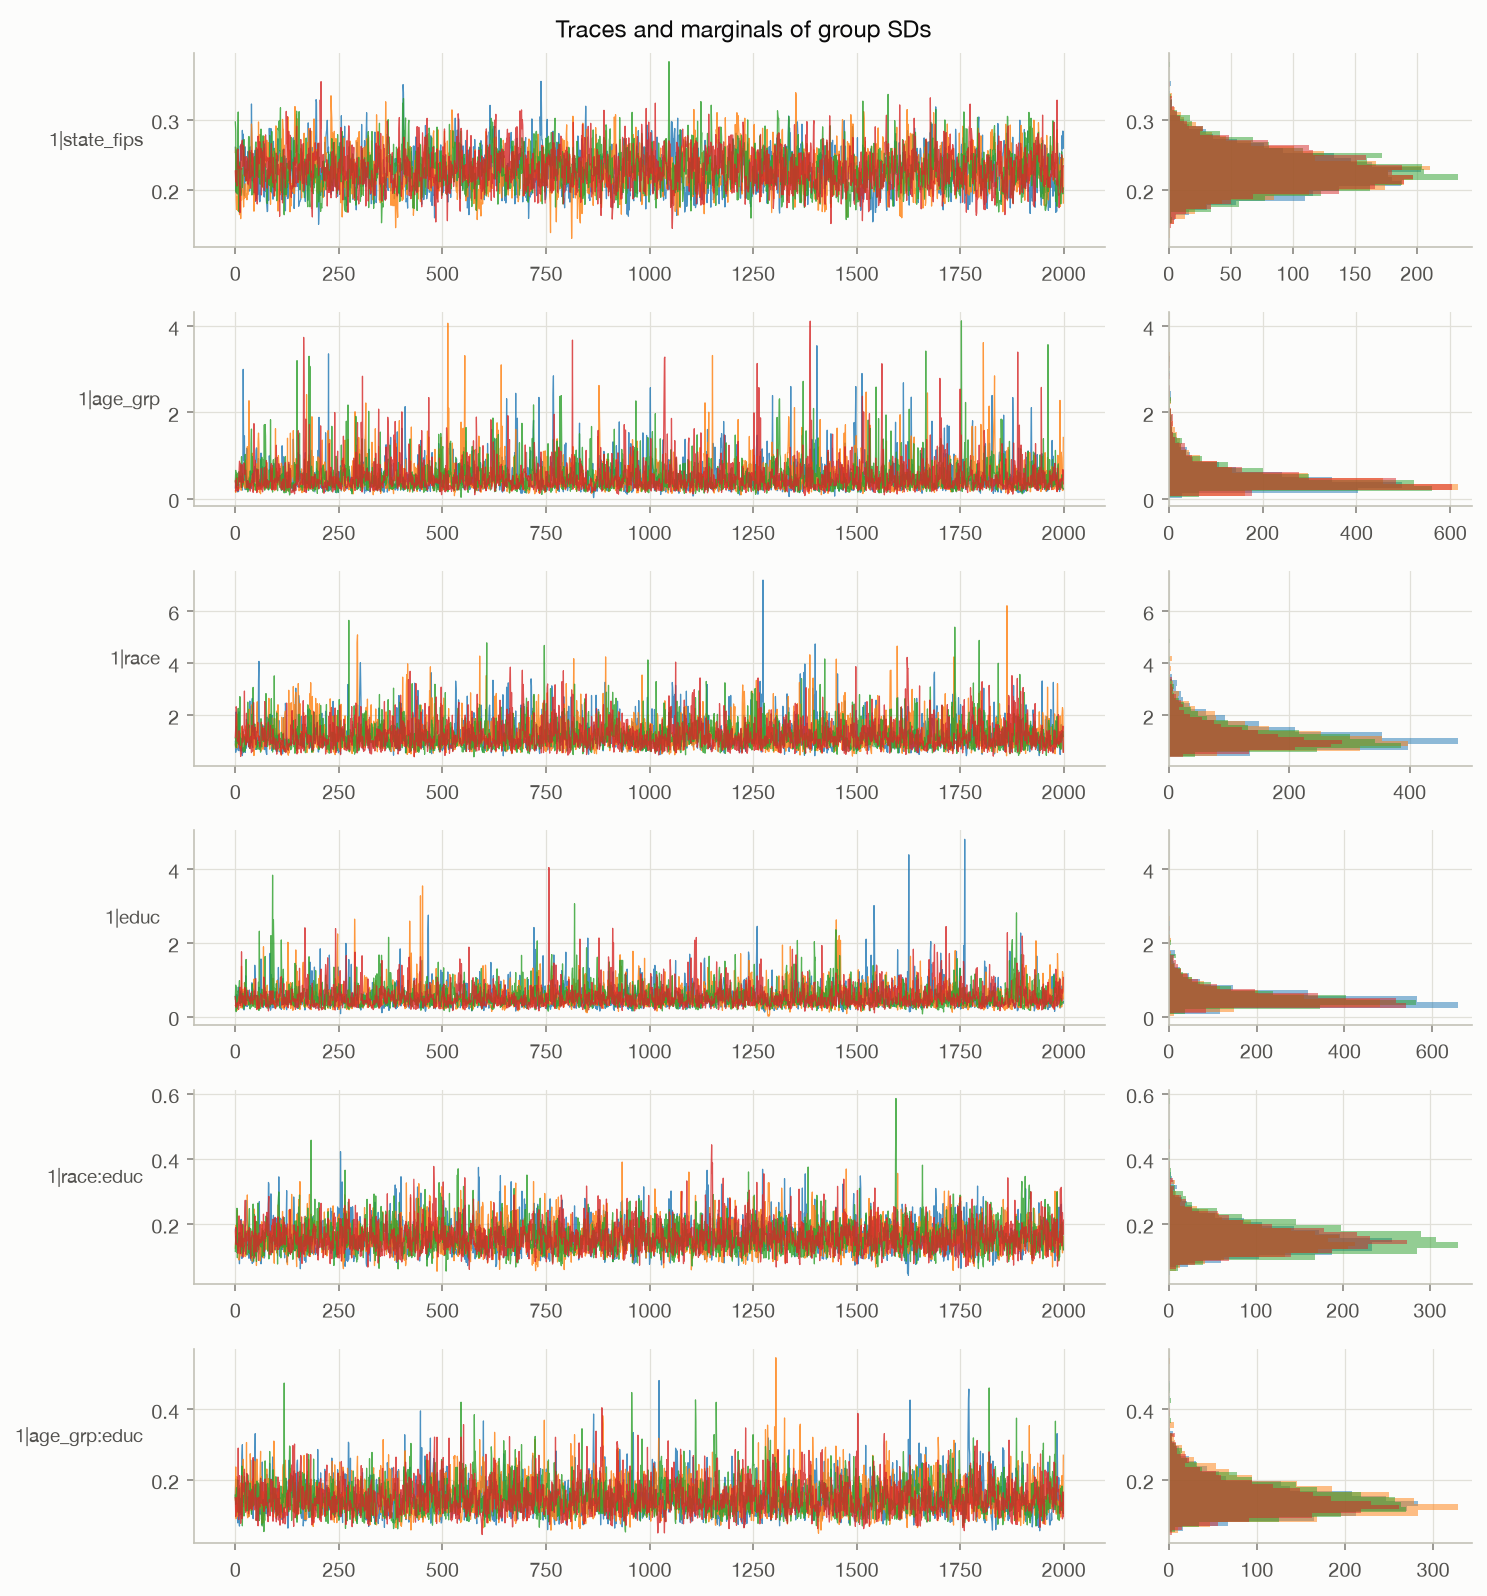

In [3]:
post = idata.posterior
sigmas = [v for v in post.data_vars if v.endswith('_sigma')]
fig, axes = plt.subplots(len(sigmas), 2, figsize=(10, 1.8 * len(sigmas)),
                         gridspec_kw={'width_ratios': [3, 1]})
for row, v in zip(axes, sigmas):
    for c in post.chain.values:
        x = post[v].sel(chain=c).values
        row[0].plot(x, lw=0.6, alpha=0.8)
        row[1].hist(x, bins=30, alpha=0.5, orientation='horizontal')
    row[0].set_ylabel(v.replace('_sigma', ''), rotation=0, ha='right')
fig.suptitle('Traces and marginals of group SDs')
fig.tight_layout()

## 3. Energy
The marginal energy and the energy transitions should have similar spread; a much narrower transition distribution means the sampler struggles to reach the tails (low E-BFMI).

findfont: Failed to find font weight semibold for Helvetica Neue, now using 700.


E-BFMI by chain (want > 0.3): [0.8  0.74 0.77 0.73]


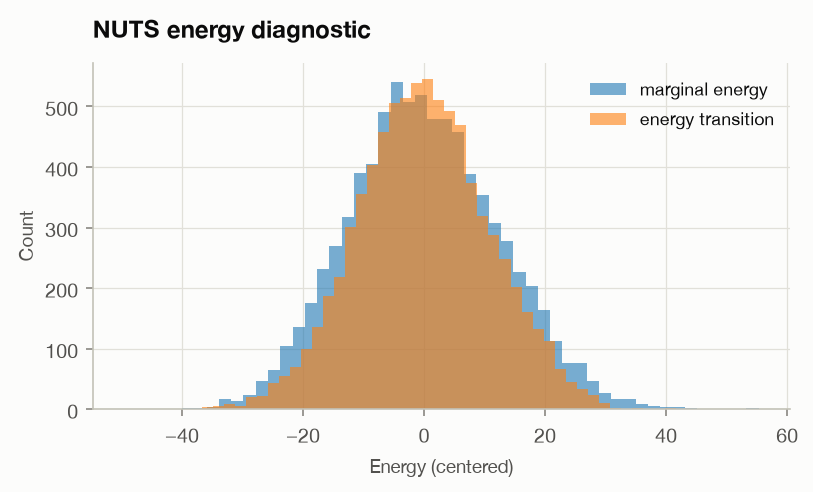

In [4]:
E = idata.sample_stats['energy'].values
dE = np.diff(E, axis=1)
bfmi = (dE ** 2).mean(axis=1) / E.var(axis=1)
print('E-BFMI by chain (want > 0.3):', bfmi.round(2))
fig, ax = plt.subplots(figsize=(6, 3))
ax.set(xlabel="Energy (centered)", ylabel="Count", title="NUTS energy diagnostic")
ax.hist((E - E.mean()).ravel(), bins=50, alpha=0.6, label='marginal energy')
ax.hist(dE.ravel(), bins=50, alpha=0.6, label='energy transition')
ax.legend();

## 4. State effects
Posterior state intercepts (log-odds), with 95% intervals: partial pooling toward the 2020-vote prediction.

Text(0.0, 1.0, 'State random intercepts')

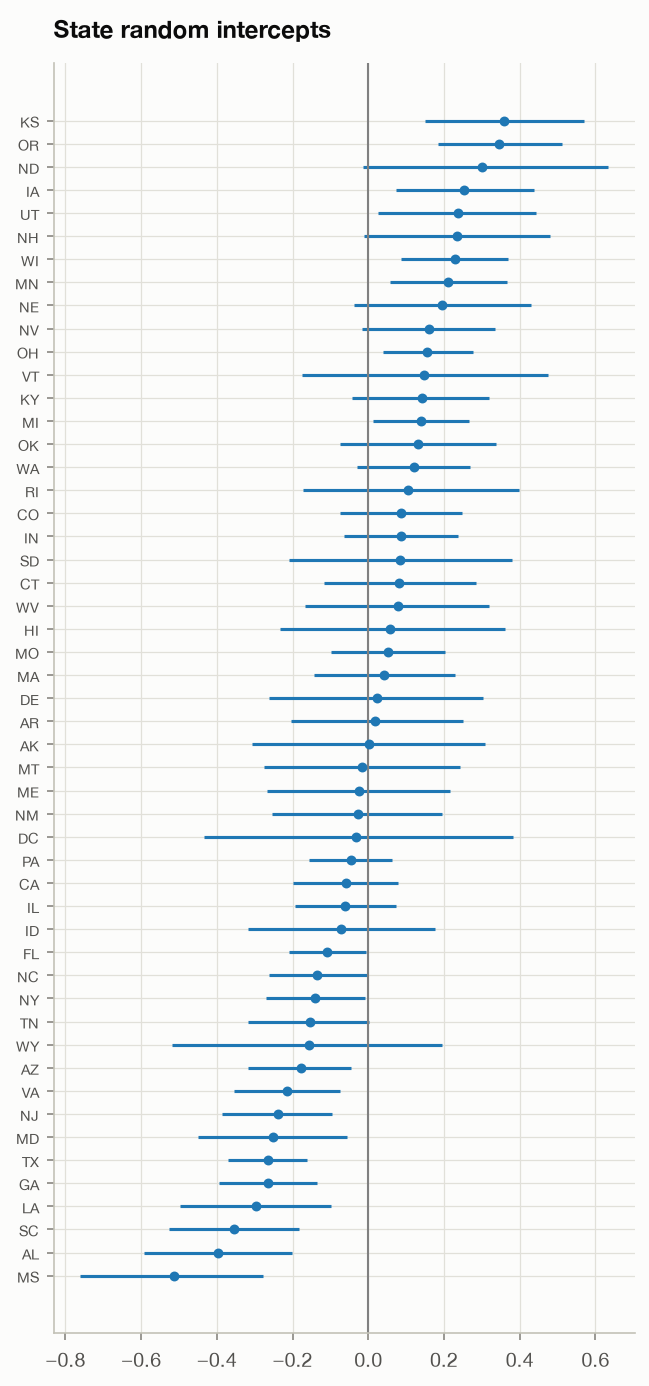

In [5]:
st = post['1|state_fips']
dim = [d for d in st.dims if d not in ('chain', 'draw')][0]
draws = st.stack(s=('chain', 'draw')).transpose(dim, 's').values
labels = [ABBR.get(int(float(x)), x) for x in st[dim].values]
order = np.argsort(draws.mean(1))
lo, hi = np.percentile(draws, [2.5, 97.5], axis=1)
fig, ax = plt.subplots(figsize=(5, 11))
y = np.arange(len(order))
ax.hlines(y, lo[order], hi[order], lw=1.5)
ax.scatter(draws.mean(1)[order], y, s=14, zorder=3)
ax.set_yticks(y, [labels[i] for i in order], fontsize=7)
ax.axvline(0, color='grey', lw=1)
ax.set_title('State random intercepts')

## What to do if checks fail
- Increase draws: `make estimate DRAWS=2000`
- Already applied: sex as a fixed effect (a 2-level random effect caused divergences) and target_accept=0.99.
- Drop the weakest interaction term (often `age_grp:educ`) and refit